In [ ]:
## Script for extracting and processing head motion data from fmri recordings
# Run with python 3.10 fMRI env
# James Fodor 2024

import numpy as np
import matplotlib.pyplot as plt

# Define parameters
sub_id = '19'
num_runs = 8
fd_index = 16 # index in confounds data of framewise displacement
path = '../Data-fmri/preprocessed/sub-'+sub_id+'/func/'

# Loop over all runs to load and save data
confound_data = []
fd_data = []
for run in np.arange(1,num_runs+1):
    # Load data from confounds file
    filename = 'sub-'+sub_id+'_task-sentences_run-'+str(run)+'_desc-confounds_timeseries.tsv'
    file = np.loadtxt(path+filename, delimiter='\t', dtype='str', skiprows=1)
    confound_data.append(file)
    fd_single_run = []

    # Extract framewise displacement
    for file_TR in file:
        if file_TR[fd_index]=='n/a': # fix first TR where framewise displacement is given as n/a instead of 0
            fd_single_run.append(0)
        else:
            fd_single_run.append(file_TR[fd_index])
    fd_data.append(fd_single_run)

# Reshape and save as numpy
fd_data = np.array(fd_data, dtype=float)
print(fd_data.shape)

(8, 636)


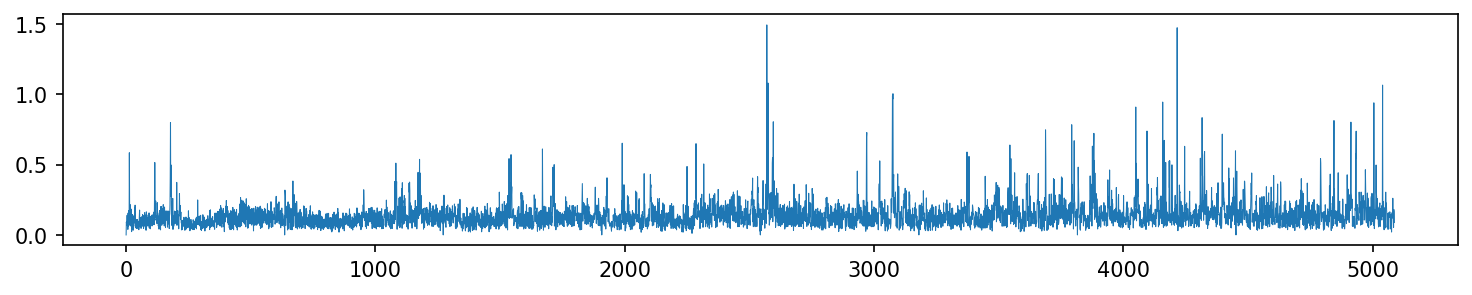

In [2]:
# Plot figure
plt.figure(figsize=(12,2), facecolor='white', dpi=150)
x_axis = np.arange(fd_data.shape[1]*num_runs)
y_axis = fd_data.flatten()
plt.plot(x_axis, y_axis, linewidth=0.5)
plt.show()

In [3]:
# Print motion averages
max_by_run = []
for run in fd_data:
    max_by_run.append(np.max(run))
print('Subject',sub_id)
print('Av run max: {:.3f}'.format(np.mean(max_by_run)))
print('Overall av: {:.3f}'.format(np.mean(y_axis)))

Subject 19
Av run max: 0.928
Overall av: 0.143
